<a href="https://colab.research.google.com/github/Shanmukh5922/Exploratory_data_analysis/blob/main/25BAI0140_EXP6_18.08.2026/Multivarient_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data Analysis of Wine Quality Dataset

This notebook replicates the steps for data analysis, descriptive statistics, and visualization as outlined in the provided document, adapted for the `WineQT (3).csv` dataset.

In [1]:
# 1. Start by importing the required libraries and loading the dataset:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Load the dataset (using the user-provided file path)
df = pd.read_csv('/content/WineQT (3).csv')

# Display First and Last 3 rows of the dataset
print("First 3 rows:")
print(df.head(3))
print("\nLast 3 rows:")
print(df.tail(3))

First 3 rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8        5   1  
2      9.8        5   2  

Last 3 rows:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
1140            6.2             0.600         0.08             2.0      0.090   
1141            5.9             0.550         0.10             2.2      0.062   
1142           

### 2. Check Data Types and Descriptive Statistics

In [2]:
# 3. Check the data types of each column
print("Data Types:")
print(df.dtypes)

# 5. Find the descriptive Statistics of the entire dataset
print("\nDescriptive Statistics:")
print(df.describe())

# Check for missing values
print("\nMissing values per column:")
print(pd.isna(df).sum())

Data Types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object

Descriptive Statistics:
       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    1143.000000       1143.000000  1143.000000     1143.000000   
mean        8.311111          0.531339     0.268364        2.532152   
std         1.747595          0.179633     0.196686        1.355917   
min         4.600000          0.120000     0.000000        0.900000   
25%         7.100000          0.392500     0.090000        1.900000   
50%         7.900000          0.520000     0.250000        2.200000   
75%         9.100000          0.6400

### 5.1 Data Cleaning (Adaptation for `WineQT (3).csv`)

The original document had specific cleaning steps for 'price', 'horsepower', and 'normalized-losses' which involved replacing '?' with mean values. For the `WineQT (3).csv` dataset, we first check for any '?' in string columns or NaNs in numeric columns. If found, we'll impute them.

In [3]:
# Check for '?' in all columns (assuming they are not expected in WineQT dataset)
for col in df.columns:
    if df[col].dtype == 'object': # Check only object type columns
        if (df[col] == '?').any():
            print(f"Column '{col}' contains '?' values. Handling them by replacing with NaN and then imputing.")
            df[col] = df[col].replace('?', np.nan).astype(float)
    # For numerical columns, fill any NaNs with the mean
    if df[col].isnull().any():
        if df[col].dtype == 'object': # Convert to numeric if it became object after replacing '?'
            df[col] = pd.to_numeric(df[col], errors='coerce')
        if pd.api.types.is_numeric_dtype(df[col]):
            mean_val = df[col].mean()
            df[col] = df[col].fillna(mean_val)
            print(f"Filled missing values in '{col}' with mean: {mean_val:.2f}")

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64


### Univariate Analysis

Univariate analysis focuses on describing a single variable.

In [4]:
# 6. Compute the measure of central tendency for the 'alcohol' column
# (Using 'alcohol' as an example numerical column from WineQT dataset)

mean_alcohol = df["alcohol"].mean()
median_alcohol = df["alcohol"].median()
mode_alcohol = df["alcohol"].mode()

print(f"Mean of Alcohol: {mean_alcohol:.2f}")
print(f"Median of Alcohol: {median_alcohol:.2f}")
print(f"Mode of Alcohol: {mode_alcohol.to_list()}")

Mean of Alcohol: 10.44
Median of Alcohol: 10.20
Mode of Alcohol: [9.5]


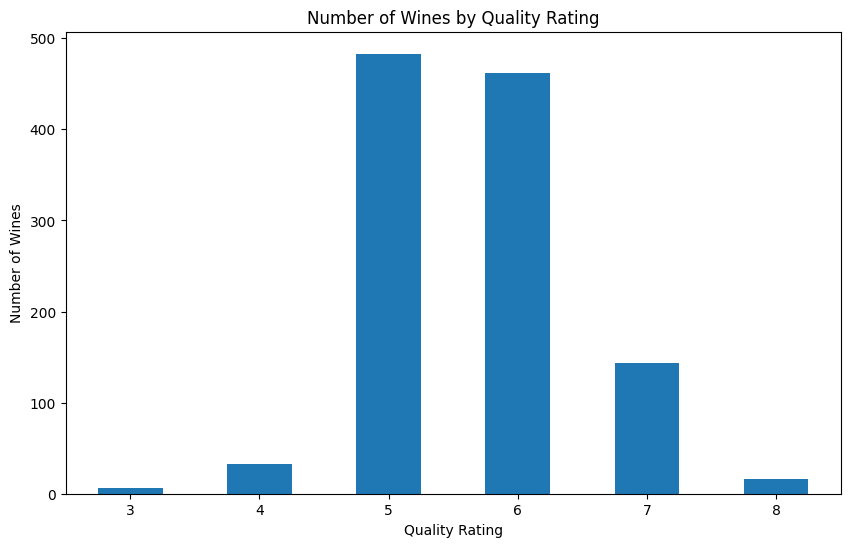

In [5]:
# 7. Bar chart for the 'quality' column (as a categorical-like feature)
# We'll plot the count of each quality rating.

plt.figure(figsize=(10,6))
df['quality'].value_counts().sort_index().plot(kind='bar', figsize=(10,6))
plt.title("Number of Wines by Quality Rating")
plt.ylabel('Number of Wines')
plt.xlabel('Quality Rating')
plt.xticks(rotation=0)
plt.show()

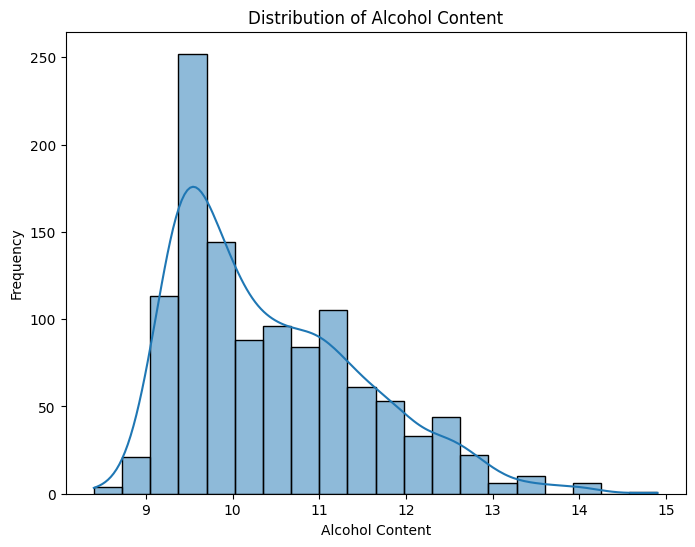

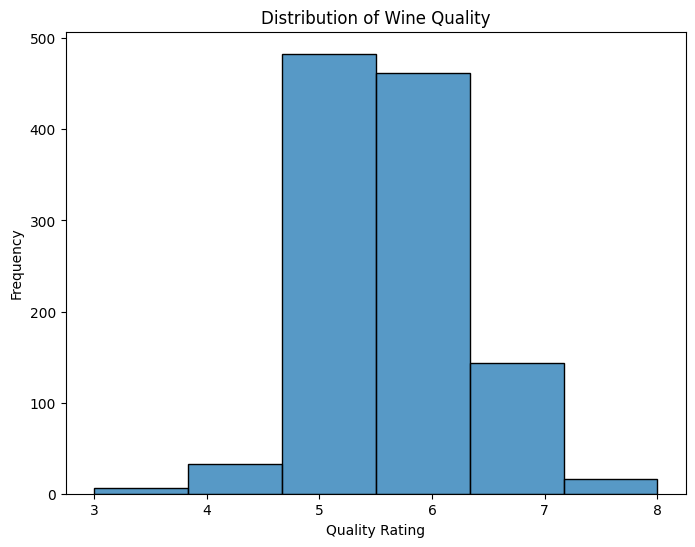

In [6]:
# 8. Distribution plot for 'alcohol'
# Using histplot as distplot is deprecated

plt.figure(figsize=(8,6))
sns.histplot(df["alcohol"], kde=True, bins=20)
plt.title("Distribution of Alcohol Content")
plt.xlabel("Alcohol Content")
plt.ylabel("Frequency")
plt.show()

# Distribution plot for 'quality'
plt.figure(figsize=(8,6))
sns.histplot(df["quality"], kde=False, bins=len(df['quality'].unique()))
plt.title("Distribution of Wine Quality")
plt.xlabel("Quality Rating")
plt.ylabel("Frequency")
plt.show()

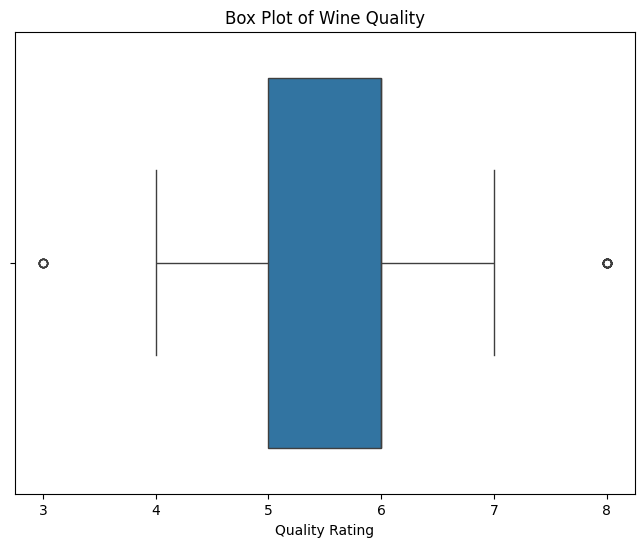

In [7]:
# Boxplot for 'quality' (as an example of numerical distribution)

plt.figure(figsize=(8,6))
sns.boxplot(x=df["quality"])
plt.title("Box Plot of Wine Quality")
plt.xlabel("Quality Rating")
plt.show()

### Bivariate Analysis

Bivariate analysis explores the relationship between two variables.

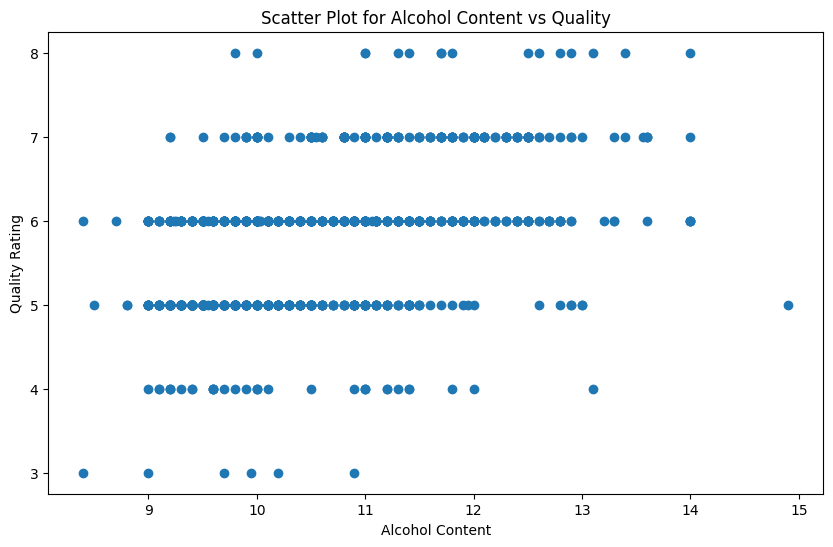

In [8]:
# 1. Scatter plot for 'alcohol' vs 'quality'

plt.figure(figsize=(10,6))
plt.scatter(df["alcohol"], df["quality"])
plt.title("Scatter Plot for Alcohol Content vs Quality")
plt.xlabel("Alcohol Content")
plt.ylabel("Quality Rating")
plt.show()

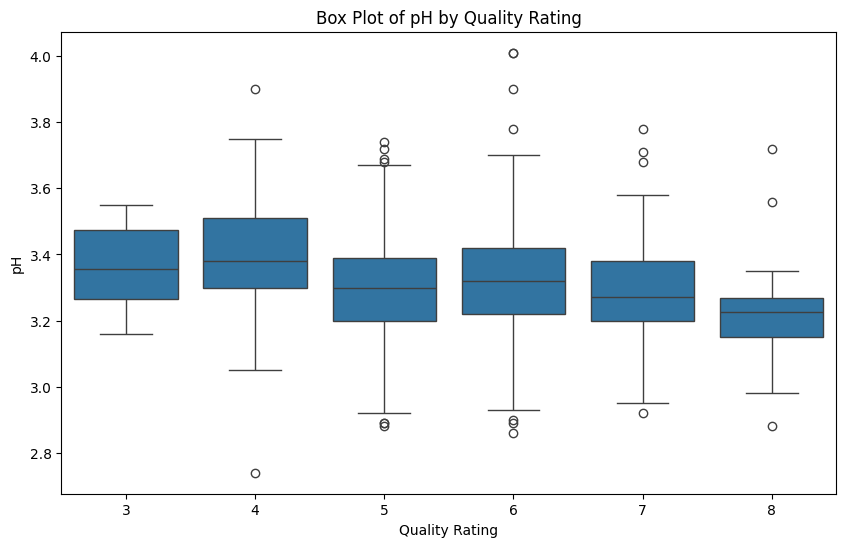

In [9]:
# 2. Box plot for 'quality' vs 'pH'
# Here 'quality' can be treated as a categorical variable for grouping.

plt.figure(figsize=(10,6))
sns.boxplot(x="quality", y="pH", data=df)
plt.title("Box Plot of pH by Quality Rating")
plt.xlabel("Quality Rating")
plt.ylabel("pH")
plt.show()

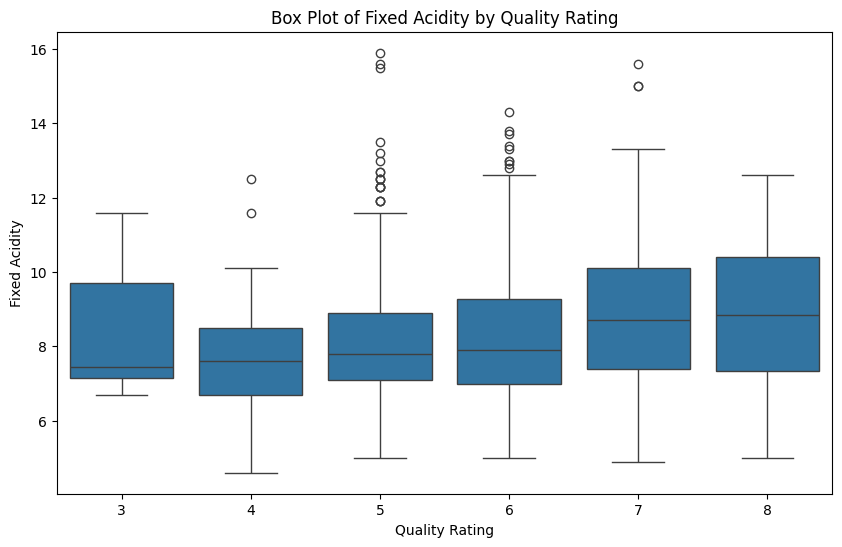

In [10]:
# 3. Box plot for 'quality' vs 'fixed acidity'

plt.figure(figsize=(10,6))
sns.boxplot(x="quality", y="fixed acidity", data=df)
plt.title("Box Plot of Fixed Acidity by Quality Rating")
plt.xlabel("Quality Rating")
plt.ylabel("Fixed Acidity")
plt.show()

### Multivariate Analysis

Multivariate analysis examines the relationships among three or more variables.

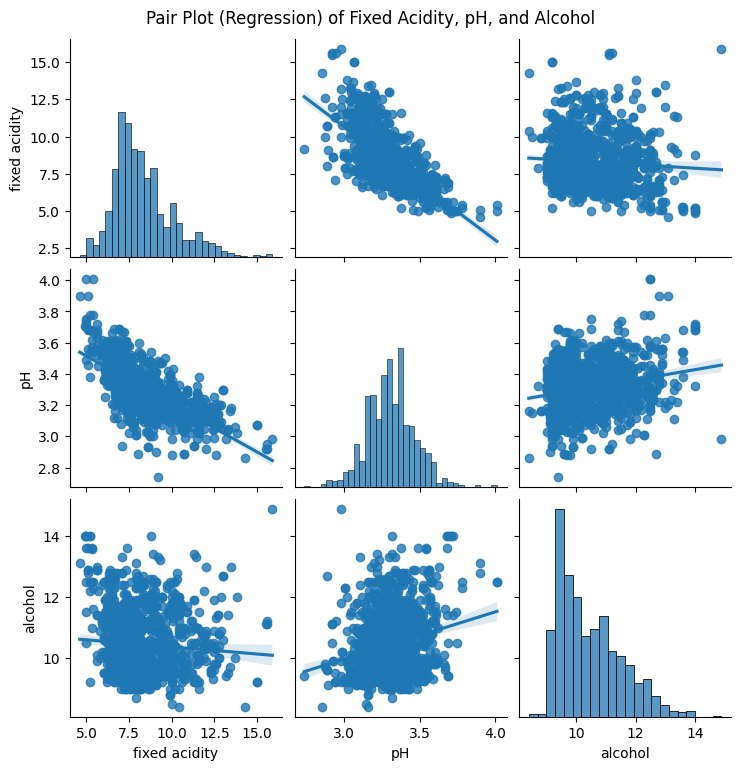

In [11]:
# 1. Pair plot with regression for selected numerical variables
# Using 'fixed acidity', 'pH', and 'alcohol'

sns.pairplot(df, vars=['fixed acidity', 'pH', 'alcohol'], kind="reg")
plt.suptitle("Pair Plot (Regression) of Fixed Acidity, pH, and Alcohol", y=1.02) # Add a title to the figure
plt.show()

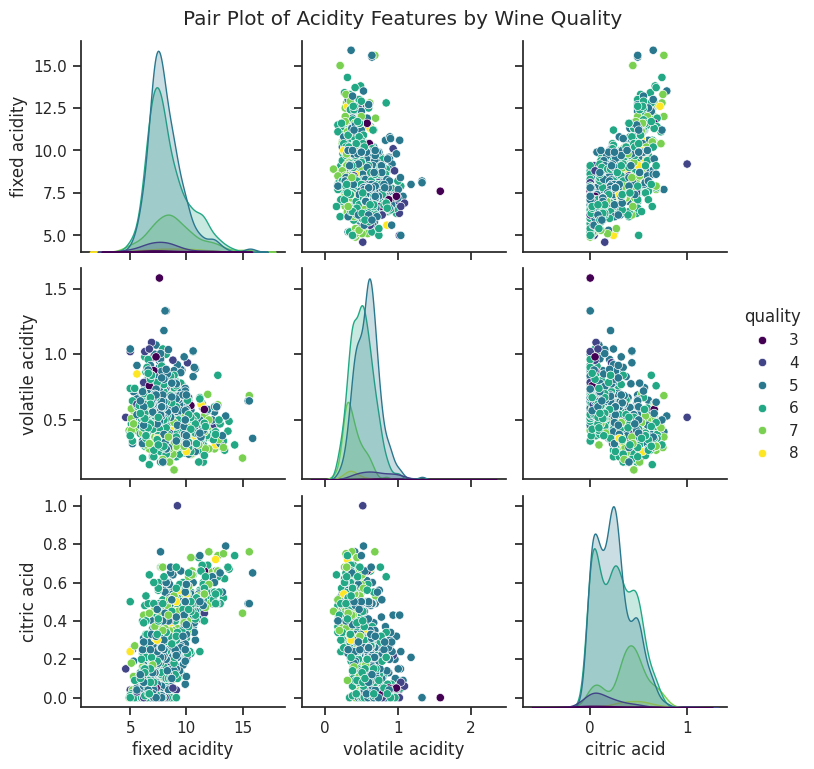

In [12]:
# 2. Pair plot by specifying the hue for 'quality'
# Using 'fixed acidity', 'volatile acidity', 'citric acid' and 'quality' for hue

sns.set(style="ticks", color_codes=True)
sns.pairplot(df, vars=['fixed acidity', 'volatile acidity', 'citric acid'], hue="quality", palette="viridis")
plt.suptitle("Pair Plot of Acidity Features by Wine Quality", y=1.02) # Add a title to the figure
plt.show()

### Correlation Analysis

Analyzing the strength and direction of linear relationships between variables.

In [13]:
# 3. Calculate the correlation coefficient for 'alcohol' and 'quality'
from scipy import stats

corr_alcohol_quality = stats.pearsonr(df["alcohol"], df["quality"])
print(f"Pearson Correlation between Alcohol and Quality:")
print(f"  Coefficient: {corr_alcohol_quality[0]:.4f}")
print(f"  P-value: {corr_alcohol_quality[1]:.4e}")

Pearson Correlation between Alcohol and Quality:
  Coefficient: 0.4849
  P-value: 1.9247e-68


In [14]:
# To find the correlation among the entire numerical records
# the columns using pearson method
correlation = df.corr(method='pearson', numeric_only=True)
print("\nCorrelation Matrix (Pearson):")
print(correlation)


Correlation Matrix (Pearson):
                      fixed acidity  volatile acidity  citric acid  \
fixed acidity              1.000000         -0.250728     0.673157   
volatile acidity          -0.250728          1.000000    -0.544187   
citric acid                0.673157         -0.544187     1.000000   
residual sugar             0.171831         -0.005751     0.175815   
chlorides                  0.107889          0.056336     0.245312   
free sulfur dioxide       -0.164831         -0.001962    -0.057589   
total sulfur dioxide      -0.110628          0.077748     0.036871   
density                    0.681501          0.016512     0.375243   
pH                        -0.685163          0.221492    -0.546339   
sulphates                  0.174592         -0.276079     0.331232   
alcohol                   -0.075055         -0.203909     0.106250   
quality                    0.121970         -0.407394     0.240821   
Id                        -0.275826         -0.007892    -0

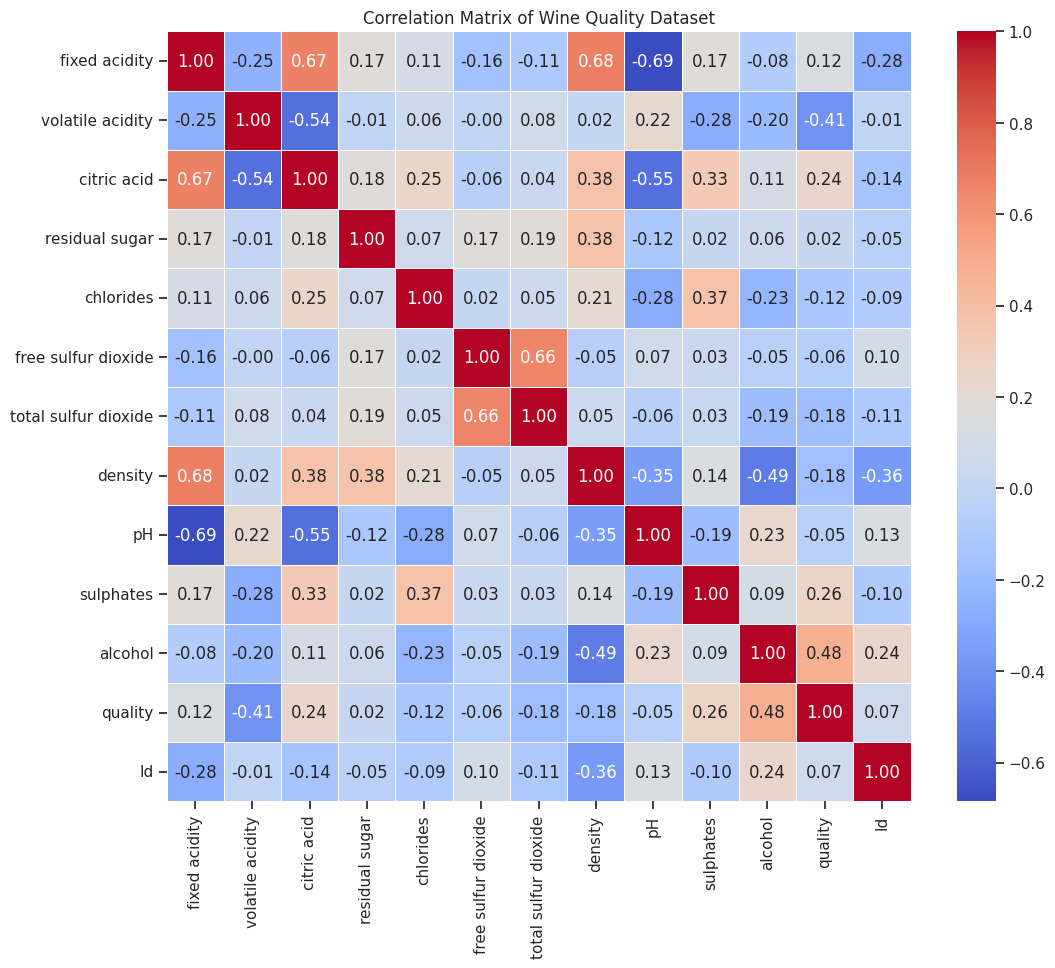

In [15]:
# 5. Visualize this correlation analysis using a heatmap.

plt.figure(figsize=(12, 10))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Wine Quality Dataset')
plt.show()